# Data Engineering & Monetization Analytics in Mobile Games
**Author:** Kanat Mukhammedkanafiya, Student at University of London (Data Science and Business Analytics)

**Суть проекта:** Data Engineering и аналитика in-app покупок (монетизации) в мобильной игре[cite: 1].
**Стек:** Python, Pandas, PostgreSQL, psycopg2, продвинутый SQL (CTE, Window functions)[cite: 1].

В этом ноутбуке мы пройдем полный цикл работы с данными:
1. **Синтез данных:** Генерация реалистичных логов игровых транзакций (user_id, timestamp, event_type, item_id, revenue)[cite: 1].
2. **ETL-процесс:** Очистка данных с помощью Pandas и загрузка в локальную базу PostgreSQL через `psycopg2`[cite: 1].
3. **Аналитика (SQL):** Расчет метрик монетизации (ARPU, ARPPU) и когортный анализ (Retention) с помощью продвинутого SQL[cite: 1].

In [1]:
import pandas as pd
import numpy as np
import psycopg2
from psycopg2.extras import execute_values
from datetime import datetime, timedelta
import warnings

warnings.filterwarnings('ignore') # Отключаем лишние предупреждения Pandas
print("Библиотеки успешно загружены!")

Библиотеки успешно загружены!


In [2]:
def generate_game_logs(num_users=5000, days=30):
    np.random.seed(42)
    start_date = datetime(2026, 9, 1)
    
    # Распределение: 90% F2P, 8% Dolphins, 2% Whales
    users = pd.DataFrame({
        'user_id': range(1, num_users + 1),
        'segment': np.random.choice(['f2p', 'dolphin', 'whale'], p=[0.90, 0.08, 0.02], size=num_users)
    })
    
    items = {'starter_pack': 1.99, 'battle_pass': 9.99, 'gem_chest': 49.99, 'legendary_chest': 99.99}
    events = []
    
    for row in users.itertuples():
        uid = row.user_id
        install_date = start_date + timedelta(days=np.random.randint(0, days), minutes=np.random.randint(0, 1440))
        events.append([uid, install_date, 'install', None, 0.0])
        
        # Логика активности в зависимости от сегмента
        active_days = np.random.randint(10, days) if row.segment == 'whale' else \
                      np.random.randint(3, 15) if row.segment == 'dolphin' else \
                      np.random.randint(1, 7)
            
        for i in range(active_days):
            session_time = install_date + timedelta(days=i, minutes=np.random.randint(10, 600))
            if session_time > start_date + timedelta(days=days): break
            events.append([uid, session_time, 'session_start', None, 0.0])
            
            # Логика покупок
            if row.segment == 'dolphin' and np.random.random() < 0.15:
                item = np.random.choice(['starter_pack', 'battle_pass'])
                events.append([uid, session_time + timedelta(minutes=5), 'purchase', item, items[item]])
            elif row.segment == 'whale' and np.random.random() < 0.40:
                item = np.random.choice(['battle_pass', 'gem_chest', 'legendary_chest'], p=[0.2, 0.5, 0.3])
                events.append([uid, session_time + timedelta(minutes=10), 'purchase', item, items[item]])

    df = pd.DataFrame(events, columns=['user_id', 'timestamp', 'event_type', 'item_id', 'revenue'])
    
    # Добавляем "грязные" данные (пропуски в датах) для этапа очистки
    corrupt_indices = np.random.choice(df.index, size=int(len(df)*0.01), replace=False)
    df.loc[corrupt_indices, 'timestamp'] = np.nan
    
    return df.sort_values(by='timestamp').reset_index(drop=True)

# Генерируем датасет и смотрим на первые 5 строк
raw_df = generate_game_logs(num_users=2000) # Взяли 2000 юзеров для скорости тестирования
raw_df.head()

,user_id,timestamp,event_type,item_id,revenue
0,854,2026-09-01 00:37:00,install,None,0.0
1,1098,2026-09-01 00:57:00,install,None,0.0
2,591,2026-09-01 01:39:00,install,None,0.0
3,591,2026-09-01 01:57:00,session_start,None,0.0
4,203,2026-09-01 03:15:00,install,None,0.0


In [3]:
# 1. Удаляем строки без времени (те самые 1% "грязных" данных)
clean_df = raw_df.dropna(subset=['timestamp']).copy()

# 2. Обрабатываем пустые значения (Nan) в покупках
clean_df['revenue'] = clean_df['revenue'].fillna(0.0)
clean_df['item_id'] = clean_df['item_id'].fillna('none')

# Смотрим информацию о чистом датасете
print(f"Исходных строк: {len(raw_df)}")
print(f"Строк после очистки: {len(clean_df)}")
clean_df.info()

Исходных строк: 9922
Строк после очистки: 9823
<class 'pandas.core.frame.DataFrame'>
Index: 9823 entries, 0 to 9822
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   user_id     9823 non-null   int64         
 1   timestamp   9823 non-null   datetime64[ns]
 2   event_type  9823 non-null   object        
 3   item_id     9823 non-null   object        
 4   revenue     9823 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 460.5+ KB


In [5]:
# Создаем таблицу пользователей (cohorts) - берем дату первого появления в игре
users_df = clean_df.groupby('user_id', as_index=False)['timestamp'].min()
users_df.rename(columns={'timestamp': 'first_seen_at'}, inplace=True)

# Таблица всех событий (установок, сессий, покупок)
events_df = clean_df[['user_id', 'timestamp', 'event_type', 'item_id', 'revenue']].copy()

print(f"Подготовлено к загрузке в БД:")
print(f"Пользователей: {len(users_df)}")
print(f"Событий: {len(events_df)}")
import sqlite3

# Создаем или подключаемся к локальному файлу базы данных SQLite
DB_PATH = "game_analytics.db"

create_tables_query = """
CREATE TABLE IF NOT EXISTS users (
    user_id INTEGER PRIMARY KEY,
    first_seen_at TIMESTAMP NOT NULL
);

CREATE TABLE IF NOT EXISTS events (
    event_id INTEGER PRIMARY KEY AUTOINCREMENT,
    user_id INTEGER,
    event_timestamp TIMESTAMP NOT NULL,
    event_type TEXT NOT NULL,
    item_id TEXT,
    revenue REAL NOT NULL,
    FOREIGN KEY(user_id) REFERENCES users(user_id) ON DELETE CASCADE
);

CREATE INDEX IF NOT EXISTS idx_events_user_id ON events(user_id);
CREATE INDEX IF NOT EXISTS idx_events_timestamp ON events(event_timestamp);
"""

# В SQLite для параметризованных запросов используются знаки вопроса (?)
insert_users_query = """
INSERT INTO users (user_id, first_seen_at) VALUES (?, ?)
ON CONFLICT (user_id) DO NOTHING;
"""

insert_events_query = """
INSERT INTO events (user_id, event_timestamp, event_type, item_id, revenue)
VALUES (?, ?, ?, ?, ?);
"""

try:
    # Подключаемся к базе (файл game_analytics.db появится в папке с проектом)
    with sqlite3.connect(DB_PATH) as conn:
        cur = conn.cursor()
        
        # 1. Создаем таблицы
        cur.executescript(create_tables_query)
        
        # 2. Конвертируем DataFrame в список кортежей (SQLite не понимает numpy типы напрямую, 
        # поэтому приводим даты к строкам)
        users_df['first_seen_at'] = users_df['first_seen_at'].astype(str)
        events_df['timestamp'] = events_df['timestamp'].astype(str)
        
        users_values = list(users_df.itertuples(index=False, name=None))
        events_values = list(events_df.itertuples(index=False, name=None))
        
        # 3. Быстрая пакетная вставка (в SQLite используется executemany)
        cur.executemany(insert_users_query, users_values)
        cur.executemany(insert_events_query, events_values)
        
        # Фиксируем изменения
        conn.commit()
            
    print("УСПЕХ: Все данные успешно загружены в SQLite (файл game_analytics.db)!")
    
except Exception as e:
    print(f"ОШИБКА: {e}")

Подготовлено к загрузке в БД:
Пользователей: 2000
Событий: 9823
УСПЕХ: Все данные успешно загружены в SQLite (файл game_analytics.db)!


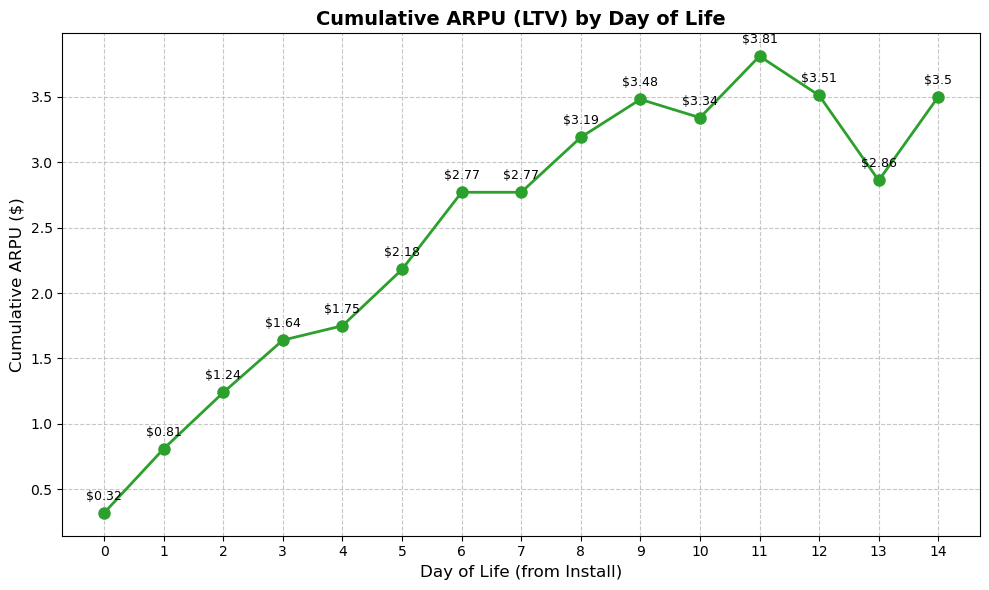

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import sqlite3

# Подключаемся к базе
conn = sqlite3.connect("game_analytics.db")

# Тот самый сложный запрос, который ты только что выполнил в DBeaver
ltv_query = """
WITH user_cohorts AS (
    SELECT user_id, DATE(first_seen_at) as install_date
    FROM users
),
daily_revenue AS (
    SELECT 
        c.user_id,
        CAST(JULIANDAY(DATE(e.event_timestamp)) - JULIANDAY(c.install_date) AS INTEGER) as lifetime_day,
        SUM(e.revenue) as daily_revenue
    FROM user_cohorts c
    JOIN events e ON c.user_id = e.user_id
    WHERE e.event_type IN ('session_start', 'purchase')
    GROUP BY c.user_id, lifetime_day
),
cumulative_user_revenue AS (
    SELECT 
        user_id,
        lifetime_day,
        SUM(daily_revenue) OVER (
            PARTITION BY user_id 
            ORDER BY lifetime_day
            ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
        ) as cumulative_revenue
    FROM daily_revenue
)
SELECT 
    lifetime_day,
    COUNT(DISTINCT user_id) as active_users,
    ROUND(SUM(cumulative_revenue) / (SELECT COUNT(DISTINCT user_id) FROM users), 2) as arpu_cumulative
FROM cumulative_user_revenue
WHERE lifetime_day <= 14
GROUP BY lifetime_day
ORDER BY lifetime_day;
"""

# Выгружаем результат в DataFrame
ltv_df = pd.read_sql(ltv_query, conn)

# Строим красивый график
plt.figure(figsize=(10, 6))
plt.plot(ltv_df['lifetime_day'], ltv_df['arpu_cumulative'], marker='o', color='#2ca02c', linewidth=2, markersize=8)

plt.title('Cumulative ARPU (LTV) by Day of Life', fontsize=14, fontweight='bold')
plt.xlabel('Day of Life (from Install)', fontsize=12)
plt.ylabel('Cumulative ARPU ($)', fontsize=12)
plt.xticks(range(0, 15))
plt.grid(True, linestyle='--', alpha=0.7)

# Добавляем подписи значений прямо на график
for i, val in enumerate(ltv_df['arpu_cumulative']):
    plt.text(ltv_df['lifetime_day'][i], val + 0.1, f"${val}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# Закрываем соединение с БД
conn.close()